In [2]:
import numpy as np
import matplotlib.pyplot as plt
import re
import os
import ase.io as aio



In [3]:

def  make_folder(folder_name):
     if not os.path.exists(folder_name):
        os.mkdir(folder_name)
        
        
        
def create_file(filename):
    with open(filename, 'w'):
        pass 


def make_empty_folder(folder_name):
    if not os.path.exists(folder_name):
        os.mkdir(folder_name)
    else:
        try:
            # List all files in the directory
            files = os.listdir(folder_name)

            # Iterate over each file and remove it
            for file in files:
                file_path = os.path.join(folder_name, file)
                if os.path.isfile(file_path):
                    os.remove(file_path)
                    #print(f"File '{file_path}' removed successfully.")
        except OSError as e:
            print(f"Error: {e.strerror}")

def find_folder_by_name(root_path, folder_name):
    folders=[]
    
    for root, dirs, files in os.walk(root_path):
        if folder_name in dirs:
             folders.append(os.path.join(root, folder_name))
    return np.sort(folders)


In [4]:
def get_initial_info(trj):
    pattern= r"TIMESTEP"
    header=8
    N_H=0
    N_O=0
    N_Fe=0
    #SCV structure (1uc)
    N_OS_uc=8    # number oxygen in first outer layer/uc
    N_FeS_uc=4   # number of iron in first outer layer/uc
    N_FeS2_uc=3  # number of iron  second/outer layer/uc
    with open(trj, 'r') as file:

        for count, line in enumerate(file):     
            if  re.search(pattern, line) and count !=0 :
                break
                
            split_line=line.split()   
            if count == 3:
                N_atom=float(split_line[0])
            if count == 5:
                L_x=float(split_line[1])
            if count == 7:
                L_z=float(split_line[1])
            #position block
            if count > header:        
                if split_line[1] == '1':
                   N_H+=1
                if split_line[1] == '2':
                   N_O+=1   
                if split_line[1] == '3':
                   N_Fe+=1   
        L_y=L_x
        
        #replica
        for n in range(1,10):
            if 8 < L_x/n < 9:
                n_replica=n
                
        if N_atom != N_H+N_O+N_Fe:
            print("ATOM LOST")
        
        f=n_replica**2
        N_water=int(N_H/2)
        N_Fe_uc=int(N_Fe/f)
        N_O_uc=int((N_O-N_water)/f)
        w_uc=float(N_water/f/2)
        N_OS=N_OS_uc*f
        N_FeS=N_FeS_uc*f
        N_FeS2= N_FeS2_uc*f
        diag_lenght=np.sqrt(L_x**2+L_y**2)
        print("L_x = L_y = ", L_x)
        print("L_z = ", L_z)
        print("Diagonal= ", diag_lenght)
        print("N_O_uc = ",  N_O_uc)
        print("N_Fe_uc =",  N_Fe_uc)
        print("w_uc =",  w_uc)
        print(f"Size factor f = {f}")
        print(f"N_water = {N_water}")
        print(f"N_H = {N_H}")
        print(f"N_O = {N_O}")
        print(f"N_Fe = {N_Fe}")
        print(f"N_atom = {N_atom}")
        print(f"N_O surface = {N_OS}")
        print(f"N_Fe surface = {N_FeS}")
        print(f"N_Fe surface2 = {N_FeS2}")
        
        return(f, L_x, L_y, L_z, diag_lenght, N_water,  N_H, N_O, N_Fe, N_OS, N_FeS, N_FeS2)

In [5]:

#takes: atoms in a layer
#determine exactly the surfaces positions with average of z of all atom in the surface: 
def get_layer_z(A):
    z=A[:,2]
    return np.mean(z), max(z), min(z)

def slice_height(A, z_max):
    tmp=[]
    for a in A:
        if a[2]<=z_max:
            tmp.append(a)
    return np.array(tmp)


In [6]:
def vector_distance_pbc(u,v , L_x, L_y, L_z):
    difference=[]
    
    dx=u[0]-v[0]
    dy=u[1]-v[1]
    dz=u[2]-v[2]
    
    if np.abs(dx) <= L_x/2:
        difference.append(dx)
    elif dx>0:
        difference.append(dx - L_x)
    else:
        difference.append(dx + L_x)
    
    if np.abs(dy) <= L_y/2:
        difference.append(dy)
    elif dy>0:
        difference.append(dy- L_y)
    else:
        difference.append(dy + L_y)
    
    if np.abs(dz) <= L_z/2:
        difference.append(dz)
    elif dz>0:
        difference.append(dz- L_z)
    else:
        difference.append(dz+ L_z)
    
    return np.array(difference)


import math
def cartesian_internal(u, phi_pi_periodicity ):  
    x=u[0]
    y=u[1]
    z=u[2]
    # Calculate radial distance
    r = math.sqrt(x**2 + y**2 + z**2)

    # Calculate polar angle (theta)
    theta = math.acos(z / r) if r != 0 else 0

    # Calculate azimuthal angle (phi)
    phi = math.atan2(y, x)
    if phi_pi_periodicity:
        if phi<0:
            phi = phi+np.pi

    return np.array([r, theta, phi])   

In [7]:
def get_O_cartesian_OH_internal(H_u_indx, O, H, L_x,L_y, z_max_vacuum, t):
    water_dipole=[]
    OHHH=[]
    OH_water=[]
    OH=[]
    O_alone=[]
    
    
    for i , H_index in enumerate(H_u_indx):

        if len(H_index)==0: 
                #if  O[i][2]>3.7:
                #       print(t,"attention! z O alone =",  O[i][2] )
                O_alone.append(O[i])

        elif len(H_index)==1: 

                OH_internal=cartesian_internal(vector_distance_pbc(H[H_index[0]],O[i]  , L_x, L_y, z_max_vacuum))
                OH.append([O[i],OH_internal])
                
                #if  O[i][2]>3.7:
                #       print(t,"attention! z OH =",  O[i][2] )
                
        elif len(H_index)==2:
                OH_cartesian_0=vector_distance_pbc(H[H_index[0]], O[i] , L_x, L_y, z_max_vacuum)
                OH_cartesian_1=vector_distance_pbc(H[H_index[1]], O[i] , L_x, L_y, z_max_vacuum)
                dipole=OH_cartesian_0+OH_cartesian_1
                
                OH_internal_0=cartesian_internal(OH_cartesian_0)
                OH_internal_1=cartesian_internal(OH_cartesian_1)
                dipole_internal=cartesian_internal(dipole)
                
                OH_water.append([O[i],OH_internal_0])
                OH_water.append([O[i],OH_internal_1])
                water_dipole.append([O[i],dipole_internal] )

        elif len(H_index)==3:
                #if  O[i][2]>3.7:
                #       print(t,"attention! z OHHH =",  O[i][2] )
                OH_cartesian_0=vector_distance_pbc(H[H_index[0]], O[i] , L_x, L_y, z_max_vacuum)
                OH_cartesian_1=vector_distance_pbc(H[H_index[1]], O[i] , L_x, L_y, z_max_vacuum)
                OH_cartesian_2=vector_distance_pbc(H[H_index[2]], O[i] , L_x, L_y, z_max_vacuum)
                OH_internal_0=cartesian_internal(OH_cartesian_0)
                OH_internal_1=cartesian_internal(OH_cartesian_1)
                OH_internal_2=cartesian_internal(OH_cartesian_2)
                
                OHHH.append([O[i],OH_internal_0])
                OHHH.append([O[i],OH_internal_1])
                OHHH.append([O[i],OH_internal_2])
                
        else:
              print( "attention! found H*O=", H_index, "at z=", O[i][2])  
    return water_dipole , OH_water , OH, OHHH, O_alone

In [109]:


def get_O_cartesian_OH_internal(H_u_indx, O, H, L_x,L_y, z_max_vacuum, t, phi_pi_periodicity):
    water_dipole=[]
    OHHH=[]
    OH_water=[]
    OH=[]
    O_alone=[]


    for i , H_index in enumerate(H_u_indx):

        if len(H_index)==0:
                #if  O[i][2]>3.7:
                #       print(t,"attention! z O alone =",  O[i][2] )
                O_alone.append(O[i])

        elif len(H_index)==1:

                OH_internal=cartesian_internal(vector_distance_pbc(H[H_index[0]],O[i]  , L_x, L_y, z_max_vacuum), phi_pi_periodicity)
                OH.append([O[i],OH_internal])

                #if  O[i][2]>3.7:
                #       print(t,"attention! z OH =",  O[i][2] )

        elif len(H_index)==2:
                OH_cartesian_0=vector_distance_pbc(H[H_index[0]], O[i] , L_x, L_y, z_max_vacuum)
                OH_cartesian_1=vector_distance_pbc(H[H_index[1]], O[i] , L_x, L_y, z_max_vacuum)
                dipole=OH_cartesian_0+OH_cartesian_1

                OH_internal_0=cartesian_internal(OH_cartesian_0, phi_pi_periodicity)
                OH_internal_1=cartesian_internal(OH_cartesian_1, phi_pi_periodicity)
                dipole_internal=cartesian_internal(dipole, phi_pi_periodicity)

                OH_water.append([O[i],OH_internal_0])
                OH_water.append([O[i],OH_internal_1])
                water_dipole.append([O[i],dipole_internal] )

        elif len(H_index)==3:
                #if  O[i][2]>3.7:
                #       print(t,"attention! z OHHH =",  O[i][2] )
                OH_cartesian_0=vector_distance_pbc(H[H_index[0]], O[i] , L_x, L_y, z_max_vacuum)
                OH_cartesian_1=vector_distance_pbc(H[H_index[1]], O[i] , L_x, L_y, z_max_vacuum)
                OH_cartesian_2=vector_distance_pbc(H[H_index[2]], O[i] , L_x, L_y, z_max_vacuum)
                OH_internal_0=cartesian_internal(OH_cartesian_0, phi_pi_periodicity)
                OH_internal_1=cartesian_internal(OH_cartesian_1, phi_pi_periodicity)
                OH_internal_2=cartesian_internal(OH_cartesian_2, phi_pi_periodicity)

                OHHH.append([O[i],OH_internal_0])
                OHHH.append([O[i],OH_internal_1])
                OHHH.append([O[i],OH_internal_2])

        else:
              print( "attention! found H(>4)O=", H_index, "at z=", O[i][2])
    return water_dipole , OH_water , OH, OHHH, O_alone




































def get_O_cartesian_OH_internal_water_plus_H3O(H_u_indx, O, H, L_x,L_y, z_max_vacuum, t, phi_pi_periodicity):
    water_dipole=[]
 
    OH_water=[]
    OH=[]
    O_alone=[]
    
    
    for i , H_index in enumerate(H_u_indx):

        if len(H_index)==0: 
                #if  O[i][2]>3.7:
                #       print(t,"attention! z O alone =",  O[i][2] )
                O_alone.append(O[i])

        elif len(H_index)==1: 

                OH_internal=cartesian_internal(vector_distance_pbc(H[H_index[0]],O[i]  , L_x, L_y, z_max_vacuum), phi_pi_periodicity)
                OH_water.append([O[i],OH_internal])
                
                #if  O[i][2]>3.7:
                #       print(t,"attention! z OH =",  O[i][2] )
                
        elif len(H_index)==2:
                OH_cartesian_0=vector_distance_pbc(H[H_index[0]], O[i] , L_x, L_y, z_max_vacuum)
                OH_cartesian_1=vector_distance_pbc(H[H_index[1]], O[i] , L_x, L_y, z_max_vacuum)
       
                
                OH_internal_0=cartesian_internal(OH_cartesian_0, phi_pi_periodicity)
                OH_internal_1=cartesian_internal(OH_cartesian_1, phi_pi_periodicity)

                
                OH_water.append([O[i],OH_internal_0])
                OH_water.append([O[i],OH_internal_1])
  
                
        elif len(H_index) >= 3:
                #if  O[i][2]>3.7:
                #       print(t,"attention! z of H", len(H_index), "H =",  O[i][2] )
                
                
                for h in range(len(H_index)):
                
                        OH_cartesian=vector_distance_pbc(H[H_index[h]], O[i] , L_x, L_y, z_max_vacuum)
                        OH_internal=cartesian_internal(OH_cartesian, phi_pi_periodicity)
                        OH_water.append([O[i],OH_internal])
     
    return water_dipole , OH_water , OH,  O_alone

In [9]:
def OH_z_layer_grouping(O_bond_format,  layer_bins):
    

    # Group arrays based on bins
    grouped_arrays = {category: [] for category in layer_bins}

    for combo in O_bond_format:
        O_z=combo[0][2]
        OH_internal=combo[1]
        for category, condition in layer_bins.items():
            if condition(O_z):
                grouped_arrays[category].append(OH_internal)
                break  # Break out of the loop after categorizing the array

    return grouped_arrays


In [10]:

def dict_bins_maker(names,layers):  #name of the z layers and layers contain  min and max value
    layer_bins={}
    

    for i, key in enumerate(names):
        layer_bins[key] = (lambda i=i: lambda x: layers[i] < x <= layers[i + 1])()
    
    return  layer_bins

def init_bins_rho_theta_phi(n_bin, delta, rho_o, phi_pi_periodicity):
    
    rho_bins   = np.linspace(rho_o, delta, n_bin) # arbitrary interval (delta is the cutoff)
    theta_bins = np.linspace(-1, 1, n_bin) 
    if phi_pi_periodicity:
        phi_bins   = np.linspace(0 , np.pi , n_bin)
    else:
        phi_bins   = np.linspace(-np.pi, np.pi , n_bin) 
    
    rho_bins_centers=(rho_bins[1:]+rho_bins[:-1])/2
    theta_bins_centers=(theta_bins[1:]+theta_bins[:-1])/2
    phi_bins_centers=(phi_bins[1:]+phi_bins[:-1])/2   
    
    return   rho_bins, theta_bins, phi_bins , rho_bins_centers , theta_bins_centers, phi_bins_centers


def init_combo_hist(layer_bins, n_bin):
    #histograms
   
    combo_hist  = {}

    
    # lenght to normalize
    
    hist_normalization= {}

    
    for layer in layer_bins.keys():
      
        combo_hist[layer]  =[[0]*(n_bin-1)]*(n_bin-1)

        hist_normalization[layer] = 0

    return combo_hist, hist_normalization



In [11]:

def sum_combo_hist(OH_grouped, combo_hist, theta_bins, rho_bins , hist_normalization,  density_bool ):

    for layer, bonds in OH_grouped.items():
        if len(bonds) !=0:
            theta=np.transpose(np.array(bonds))[1]
            rho=np.transpose(np.array(bonds))[0]    
            hist_normalization[layer]+=len(theta)
            combo_hist[layer]+=np.histogram2d( np.cos(theta),  rho,    bins=[ theta_bins,   rho_bins] , density=density_bool )[0]
          
    return combo_hist, hist_normalization

In [12]:



def sum_hist_theta_phi(OH_grouped, theta_hist, phi_hist, theta_bins, phi_bins ,density_bool,phi_sin_weight_bool ):

    for layer, bonds in OH_grouped.items():
        if len(bonds) !=0:
            theta=np.transpose(np.array(bonds))[1]
            phi=np.transpose(np.array(bonds))[2]    
            
            theta_hist[layer]+=np.histogram(np.cos(theta), bins=theta_bins,  density=density_bool)[0]
            
            
            
            if phi_sin_weight_bool:
                phi_weights=np.sin(theta)
                phi_hist[layer]  +=np.histogram(phi, bins=phi_bins, weights=phi_weights,  density=density_bool )[0]   
            else:
                phi_hist[layer]  +=np.histogram(phi, bins=phi_bins,  density=density_bool )[0]   
                
    return theta_hist, phi_hist   
    

In [13]:
def safe_concatenate(a,b):
    if len(a)==0:
        return b
    elif len(b)==0:
        return a
    else:
        return np.concatenate((a,b),axis=0) 

In [148]:
path_of_runs='/data/home/salvatorer26/projects/ferrite_oxide/production/production_runs/'
run_folder='full_coverage_big/run_2/'

file_trj=path_of_runs + run_folder +'trjmagnetite.dump'
h5py_files_folder=path_of_runs+ run_folder+"trajectory_h5py_files/" 

f, L_x, L_y, L_z, diag_lenght, N_water, N_H, N_O, N_Fe, N_OS, N_FeS, N_FeS2= get_initial_info(file_trj)
print(h5py_files_folder)

surface_selection='d'





phi_pi_periodicity='True'     # True: sin(theta) weighted average for phi  (2D plot always False!)
density_bool=False           # density histogram directly 

rho_o=0.9
delta=1.19

#z_max=41-delta       #max distance from the surface for O 25 or 40   
z_max=40
z_max_H=z_max+delta           #max distance from the surface for H (delta above to include the missing H at the cut)
z_max_vacuum= z_max+4*delta   #another delta of vacuum distance on top to avoid wrong PBC count


#H tree box for bonding
box_size = np.array([L_x, L_y, z_max_vacuum])  


# Histograms Init 

# Define binning
n_bins=80  #common number of bins


#z layer layers (all, oct, tet)
layers     =[-0.5, 1,  3.6 , 7.3, 40 ]


#z layer layers (all, oct, tet)
#layers     =[-0.5, 1, 3.6, 7.2, 10.6 , 13.8, 17,  21, 25, 29, 33, 37, 41-delta ]
#layers_oct =[ -0.5,   3.1,   5.1, 7.3  , 10,  13.5]
#layers_tet =[-0.5,  1, 2.12,  4.1, 7,    10.7]

# Define name of bins (all, oct, tet)
names    =["l_"+str(i) for i in np.arange(0,len(layers)-1)]



L_x = L_y =  33.584
L_z =  103.0138
Diagonal=  47.49494827873803
N_O_uc =  72
N_Fe_uc = 50
w_uc = 98.5
Size factor f = 16
N_water = 3152
N_H = 6304
N_O = 4304
N_Fe = 800
N_atom = 11408.0
N_O surface = 128
N_Fe surface = 64
N_Fe surface2 = 48
/data/home/salvatorer26/projects/ferrite_oxide/production/production_runs/full_coverage_big/run_2/trajectory_h5py_files/


In [149]:

import h5py
from scipy.spatial import cKDTree




# Init bins as dictionary with key as layers (all, oct, tet)
layer_bins    =dict_bins_maker(names,layers)
#initialize bins of rho, theta, phi  and respective bin centers
rho_bins, theta_bins, phi_bins , rho_bins_centers , theta_bins_centers, phi_bins_centers=init_bins_rho_theta_phi(n_bins, delta, rho_o, phi_pi_periodicity)

d_rho=(rho_bins[-1]-rho_bins[0])/(n_bins-1)
d_theta=(theta_bins[-1]-theta_bins[0])/(n_bins-1)
d_phi=(phi_bins[-1]-phi_bins[0])/(n_bins-1)

#initialize histograms with zeros
combo_hist_OH      ,  norm_hist_OH        =    init_combo_hist(layer_bins, n_bins)
combo_hist_OH_water,  norm_hist_OH_water  =    init_combo_hist(layer_bins, n_bins)
combo_hist_dipole  ,  norm_hist_dipole    =    init_combo_hist(layer_bins, n_bins)






#TIME LOOP BEGIN
t=0
h5py_str='.h5py'
with h5py.File(h5py_files_folder+"H_"+surface_selection+h5py_str, 'r') as f_H, h5py.File(h5py_files_folder+"O_"+surface_selection+h5py_str, 'r') as f_O, h5py.File(h5py_files_folder+"OS_"+surface_selection+h5py_str, 'r') as f_OS:
    for k in f_H.keys(): #main time loop

        H = f_H[k][:]
        O = f_O[k][:]
        OS = f_OS[k][:]

        #add oxygen at surface to get the OH bond of dissociation
        all_O=np.concatenate((O,OS))

        # translate to 0 the surfaces (and invert the d)
        O=slice_height(all_O, z_max)
        H=slice_height(H, z_max_H)

        #H index is a list of list of H indices: the 0 index is the Oxygen, the second runs from 0 to the N_H that are within a cutoff delta to that O
        tree = cKDTree(data=H, leafsize=H.shape[0], boxsize= box_size)  #makes a tree of Hs
        H_indx = tree.query_ball_point(O, delta)                        #assign every H to an O within the cutoff and make the list of list H


        #extract from the H_indx the Oxygen in cartesian and the OH(s)in polar:
        #the output is then a list of pair [O_vect, OH]

        #dipole , OH_water , OH, O_HHH, O_alone=get_O_cartesian_OH_internal(H_indx, O, H, L_x,L_y, z_max_vacuum, t)   #not periodic distance for the z direction
        dipole , OH_water , OH, OHHH, O_alone=get_O_cartesian_OH_internal(H_indx, O, H, L_x,L_y, z_max_vacuum, t, phi_pi_periodicity)


        #use the info of the z Oxygen to group the OH by their heights: output is dictonary with layer_bins keys and vlues OH in internal
        dipole_z  = OH_z_layer_grouping(dipole,   layer_bins)
        OH_water_z= OH_z_layer_grouping(OH_water, layer_bins)
        OH_z      = OH_z_layer_grouping(OH,       layer_bins)


        #Sum the histograms
        combo_hist_OH      ,  norm_hist_OH,         = sum_combo_hist(OH_z,       combo_hist_OH,       theta_bins, rho_bins,   norm_hist_OH,       density_bool)
        combo_hist_OH_water,  norm_hist_OH_water,   = sum_combo_hist(OH_water_z, combo_hist_OH_water, theta_bins, rho_bins,   norm_hist_OH_water, density_bool )
        combo_hist_dipole  ,  norm_hist_dipole,     = sum_combo_hist(dipole_z,   combo_hist_dipole,   theta_bins, rho_bins,   norm_hist_dipole,   density_bool)

        t+=1



In [150]:
surface_selection

'd'

In [151]:

#save histograms




folder_hist=path_of_runs+run_folder+"histogram_bond_angular/"


make_folder(folder_hist)

            #name                                               #bin center                                 #hist               #normalization   
np.save(folder_hist+"combo_hist_OH_water_"+ surface_selection, (  rho_bins_centers, theta_bins_centers , combo_hist_OH_water   ,  norm_hist_OH_water ))
np.save(folder_hist+"combo_hist_OH_"+ surface_selection, (  rho_bins_centers, theta_bins_centers , combo_hist_OH   ,  norm_hist_OH))



np.save(folder_hist+'tot_time.txt', t)

/data/home/salvatorer26/.local/lib/python3.8/site-packages/numpy/lib/npyio.py:501: VisibleDeprecationWarning: Creating an ndarray from ragged nested sequences (which is a list-or-tuple of lists-or-tuples-or ndarrays with different lengths or shapes) is deprecated. If you meant to do this, you must specify 'dtype=object' when creating the ndarray.
  arr = np.asanyarray(arr)


In [74]:



#ALL TOGETHER RUN OH plu H2O (better the previous)

#import h5py
#from scipy.spatial import cKDTree
#
#
#
#control_u='u'   #DONT  #surface down already adjusted in h5py file
## Init bins as dictionary with key as layers (all, oct, tet)
#layer_bins    =dict_bins_maker(names,layers)
##initialize bins of rho, theta, phi  and respective bin centers
#rho_bins, theta_bins, phi_bins , rho_bins_centers , theta_bins_centers, phi_bins_centers=init_bins_rho_theta_phi(n_bins, delta, rho_o, phi_pi_periodicity)
#
#d_rho=(rho_bins[-1]-rho_bins[0])/(n_bins-1)
#d_theta=(theta_bins[-1]-theta_bins[0])/(n_bins-1)
#d_phi=(phi_bins[-1]-phi_bins[0])/(n_bins-1)
#
##initialize histograms with zeros
#combo_hist_OH      ,  norm_hist_OH        =    init_combo_hist(layer_bins, n_bins)
#combo_hist_OH_water,  norm_hist_OH_water  =    init_combo_hist(layer_bins, n_bins)
#combo_hist_dipole  ,  norm_hist_dipole    =    init_combo_hist(layer_bins, n_bins) 
# 
#
#
#
#
#
##TIME LOOP BEGIN
#t=0
#h5py_str='.h5py'
#with h5py.File(h5py_files_folder+"H_"+surface_selection+h5py_str, 'r') as f_H, h5py.File(h5py_files_folder+"O_"+surface_selection+h5py_str, 'r') as f_O, h5py.File(h5py_files_folder+"OS_"+surface_selection+h5py_str, 'r') as f_OS:
#    for k in f_H.keys(): #main time loop
#      
#        H = f_H[k][:]
#        O = f_O[k][:]
#        OS = f_OS[k][:]
#           
#        #add oxygen at surface to get the OH bond of dissociation
#        all_O=np.concatenate((O,OS))
#
#        # translate to 0 the surfaces (and invert the d)
#        O=slice_height(all_O, z_max)  
#        H=slice_height(H, z_max_H)  
#
#        #H index is a list of list of H indices: the 0 index is the Oxygen, the second runs from 0 to the N_H that are within a cutoff delta to that O 
#        tree = cKDTree(data=H, leafsize=H.shape[0], boxsize= box_size)  #makes a tree of Hs
#        H_indx = tree.query_ball_point(O, delta)                        #assign every H to an O within the cutoff and make the list of list H
#     
#
#        #extract from the H_indx the Oxygen in cartesian and the OH(s)in polar:
#        #the output is then a list of pair [O_vect, OH]
#        
#        #dipole , OH_water , OH, O_HHH, O_alone=get_O_cartesian_OH_internal(H_indx, O, H, L_x,L_y, z_max_vacuum, t)   #not periodic distance for the z direction
#        dipole , OH_water , OH, O_alone=get_O_cartesian_OH_internal_water_plus_H3O(H_indx, O, H, L_x,L_y, z_max_vacuum, t, phi_pi_periodicity)   #not periodic distance for the z direction
#    
#
#        #use the info of the z Oxygen to group the OH by their heights: output is dictonary with layer_bins keys and vlues OH in internal
#        dipole_z  = OH_z_layer_grouping(dipole,   layer_bins)
#        OH_water_z= OH_z_layer_grouping(OH_water, layer_bins)
#        OH_z      = OH_z_layer_grouping(OH,       layer_bins)
#
#
#        #Sum the histograms
#        combo_hist_OH      ,  norm_hist_OH,         = sum_combo_hist(OH_z,       combo_hist_OH,       theta_bins, rho_bins,   norm_hist_OH,       density_bool)
#        combo_hist_OH_water,  norm_hist_OH_water,   = sum_combo_hist(OH_water_z, combo_hist_OH_water, theta_bins, rho_bins,   norm_hist_OH_water, density_bool )
#        combo_hist_dipole  ,  norm_hist_dipole,     = sum_combo_hist(dipole_z,   combo_hist_dipole,   theta_bins, rho_bins,   norm_hist_dipole,   density_bool)
#    
#        t+=1
#    

In [165]:
#LOAD
load_hist_OH_water_u=np.load(folder_hist+"combo_hist_OH_water_d.npy", allow_pickle= True)
load_hist_OH_water_d=np.load(folder_hist+"combo_hist_OH_water_d.npy", allow_pickle= True)
load_hist_OH_u=np.load(folder_hist+"combo_hist_OH_u.npy", allow_pickle= True)
load_hist_OH_d=np.load(folder_hist+"combo_hist_OH_d.npy", allow_pickle= True)

In [170]:
rho_bin_centers=load_hist_OH_water_d[0]
theta_bin_centers=load_hist_OH_water_d[1]

d_theta=(theta_bins[-1]-theta_bins[0])/(n_bins-2)
d_rho=(rho_bins[-1]-rho_bins[0])/(n_bins-2)
dA=d_theta*d_rho
load_hist_OH_water={}
load_hist_OH={}
for key in load_hist_OH_water_u[2]:
    load_hist_OH_water[key]=load_hist_OH_water_u[2][key]+load_hist_OH_water_d[2][key]
    load_hist_OH[key]=load_hist_OH_u[2][key]+load_hist_OH_d[2][key]




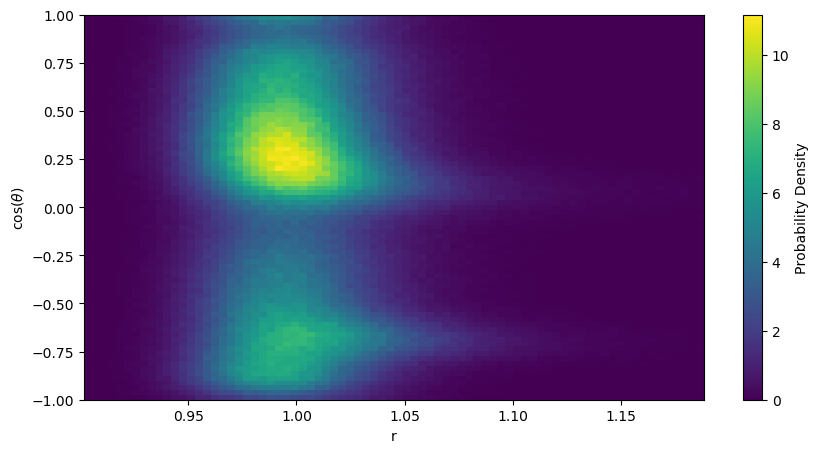

In [176]:

# Plot the histogram
n_start=0
n_end=78
plt.figure(figsize=(10, 5))
plt.imshow( np.array(load_hist_OH_water['l_1'][:,n_start:n_end])/ np.sum(load_hist_OH_water['l_1'][:,n_start:n_end])/dA , interpolation='nearest', origin='lower',extent= ( rho_bins_centers[n_start] , rho_bins_centers[n_end],  -1,1  ), aspect='auto' )
plt.colorbar(label='Probability Density')
plt.xlabel('r')
plt.ylabel(r'cos($\theta$)')
#plt.title('OH of Water')
 
#plt.tick_params(axis='x', which='major', length=18) 


save_path="/data/home/salvatorer26/Desktop/group_meeting/bond_theta_2d_OH_water_separated"
#plt.savefig(f"{save_path}/OH_water_first", bbox_inches="tight", facecolor="white", transparent=True, dpi=300)
plt.show()


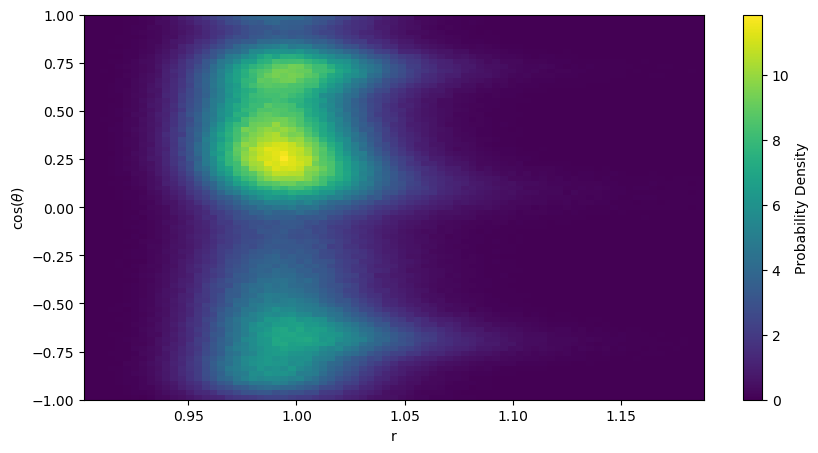

In [147]:
all_OH_first=(combo_hist_OH_water['l_1']+combo_hist_OH['l_1']+combo_hist_OH['l_0'])

norm_all_OH_first=all_OH_first/np.sum(all_OH_first)/(d_rho*d_theta)



# Plot the histogram
n_start=0
n_end=78
plt.figure(figsize=(10, 5))
plt.imshow( np.array(norm_all_OH_first) , interpolation='nearest', origin='lower',extent= ( rho_bins_centers[n_start] , rho_bins_centers[n_end],  -1,1  ), aspect='auto' )
plt.colorbar(label='Probability Density')
plt.xlabel('r')
plt.ylabel(r'cos($\theta$)')
#plt.title('OH of Water')
 
#plt.tick_params(axis='x', which='major', length=18) 


save_path="/data/home/salvatorer26/Desktop/group_meeting/bond_theta_2d_OH_water_separated"
#plt.savefig(f"{save_path}/all_OH_water_first", bbox_inches="tight", facecolor="white", transparent=True, dpi=300)
plt.show()

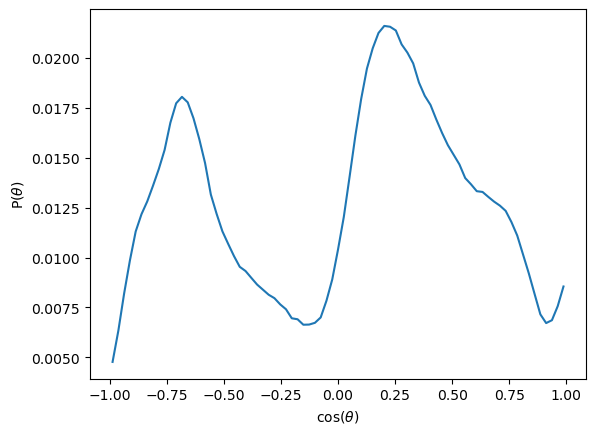

In [140]:
#marginal integrate over r
f_theta=[]
for theta in combo_hist_OH_water['l_1']/np.sum(combo_hist_OH_water['l_1']):
    f_theta.append(np.sum(theta))
    
plt.xlabel(r'cos($\theta$)')
plt.ylabel(r'P($\theta$)')
plt.plot(theta_bins_centers, f_theta)

save_path="/data/home/salvatorer26/Desktop/group_meeting/bond_theta_2d"
#plt.savefig(f"{save_path}/marg_theta", bbox_inches="tight", facecolor="white", transparent=True, dpi=300)


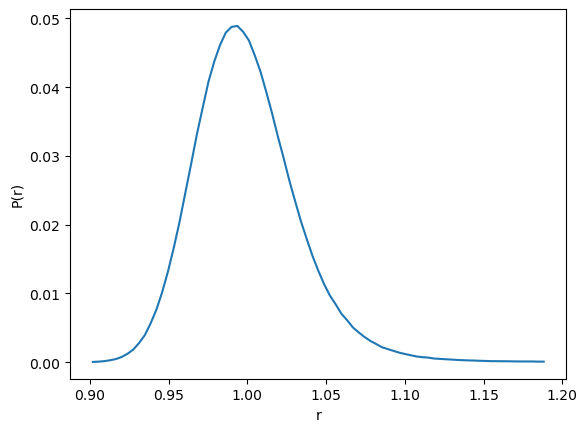

In [104]:
#marginal integrate over theta
f_rho=[]
for i in range(len(norm_combo[0])):
    f_rho.append(np.sum(norm_combo[:,i]))
plt.plot(rho_bins_centers,f_rho)
plt.xlabel('r')
plt.ylabel('P(r)')

save_path="/data/home/salvatorer26/Desktop/group_meeting/bond_theta_2d"
#plt.savefig(f"{save_path}/marg_r", bbox_inches="tight", facecolor="white", transparent=True, dpi=300)


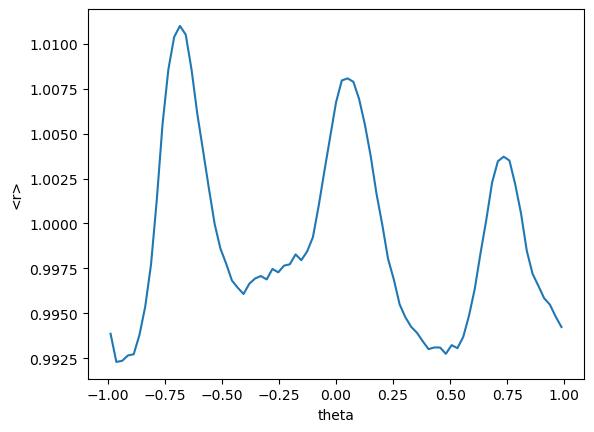

In [101]:

#Mean r given theta
rho_avg=[]

layer='l_0'

for tetha in range(len(combo_hist_OH_water[layer][0,:] )):
  #rho_distribution.append(np.mean(combo_hist_OH_water[layer][:,tetha]))
  if np.sum(combo_hist_OH_water[layer][tetha]) <= 10000:
    rho_avg.append(0)
  else:
    rho_avg.append(np.average(rho_bins_centers, weights=combo_hist_OH_water[layer][tetha] ))
    


plt.plot(theta_bins_centers, rho_avg)
plt.xlabel('theta')
plt.ylabel('<r>')



save_path="/data/home/salvatorer26/Desktop/group_meeting/bond_theta_2d"
#plt.savefig(f"{save_path}/rho_avg_0", bbox_inches="tight", facecolor="white", transparent=True, dpi=300)


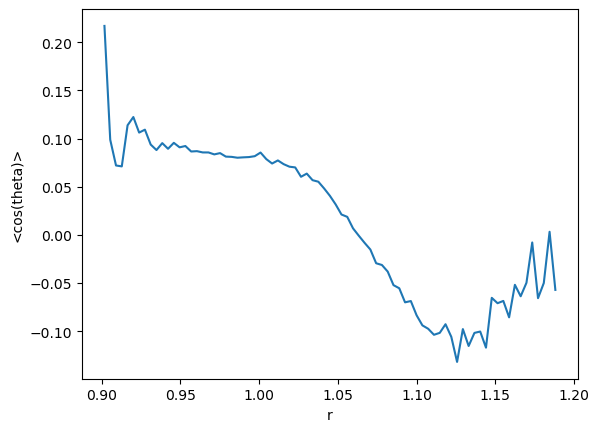

In [79]:

#Mean theta given r

theta_avg=[]

layer='l_0'

for r in range(len(combo_hist_OH_water[layer][0]   )):
  #rho_distribution.append(np.mean(combo_hist_OH_water[layer][:,r]))
  if np.sum(combo_hist_OH_water[layer][:,r]) <= 100:
    theta_avg.append(0)
  else:
    theta_avg.append(np.average(theta_bins_centers, weights=combo_hist_OH_water[layer][:,r] ))
    


plt.plot(rho_bins_centers, theta_avg)
plt.xlabel('r')
plt.ylabel('<cos(theta)>')



save_path="/data/home/salvatorer26/Desktop/group_meeting/bond_theta_2d"
#plt.savefig(f"{save_path}/avg_0", bbox_inches="tight", facecolor="white", transparent=True, dpi=300)


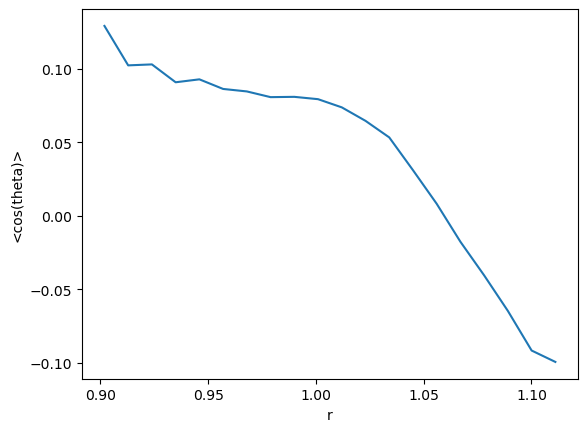

In [83]:
#coarse averages

def coarse_avg(theta_avg, rho_bins_centers, N):

    coarse_theta_avg=[]
    coarse_bins=[]
    mod=len(theta_avg)//N

    class_mod = [0]*N
    

    for i, theta in enumerate(theta_avg):
        for j in range(N):
         if i // mod  == j:
                class_mod[j]+=theta
    for j in range(N):
   
        coarse_theta_avg.append(class_mod[j]/mod)
        coarse_bins.append(rho_bins_centers[int(j*mod)])
    return np.array(coarse_theta_avg), np.array(coarse_bins)
    
N=20
coarse_theta_avg , coarse_rho_bins_centers =  coarse_avg(theta_avg,rho_bins_centers, N)



plt.plot(coarse_rho_bins_centers, coarse_theta_avg)
plt.xlabel('r')
plt.ylabel('<cos(theta)>')



save_path="/data/home/salvatorer26/Desktop/group_meeting/bond_theta_2d"
#plt.savefig(f"{save_path}/coarse_tetha_avg_5", bbox_inches="tight", facecolor="white", transparent=True, dpi=300)
    

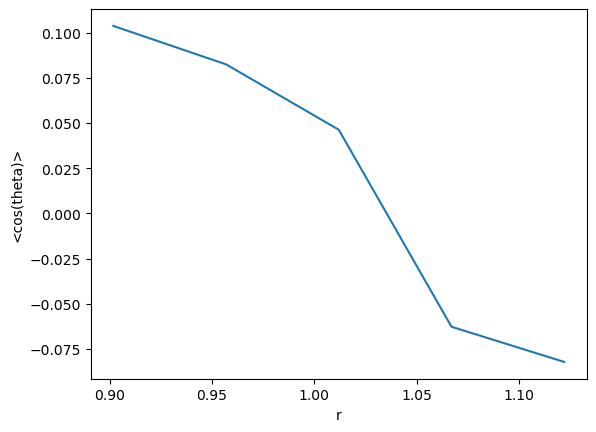

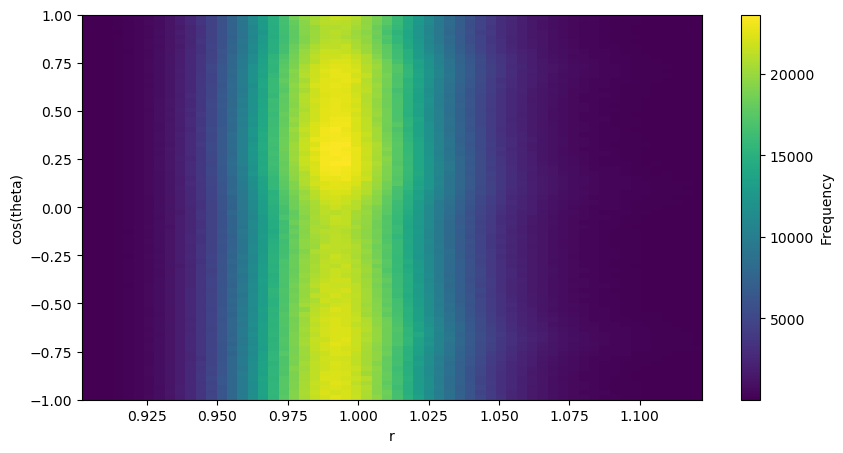

In [106]:
#all layers
all_combo_hist_OH_water=combo_hist_OH_water['l_0']+combo_hist_OH_water['l_1']+combo_hist_OH_water['l_2']

# Plot the histogram
n_start=0
n_end=60
plt.figure(figsize=(10, 5))
plt.imshow( np.array(all_combo_hist_OH_water[:,n_start:n_end]) , interpolation='nearest', origin='lower',extent= ( rho_bins_centers[n_start] , rho_bins_centers[n_end],  -1,1  ), aspect='auto' )
plt.colorbar(label='Frequency')
plt.xlabel('r')
plt.ylabel('cos(theta)')
#plt.title('2D Histogram')
 
#plt.tick_params(axis='x', which='major', length=18) 


save_path="/data/home/salvatorer26/Desktop/group_meeting/bond_theta_2d"
#plt.savefig(f"{save_path}/all_slab_all_z", bbox_inches="tight", facecolor="white", transparent=True, dpi=300)
plt.show()

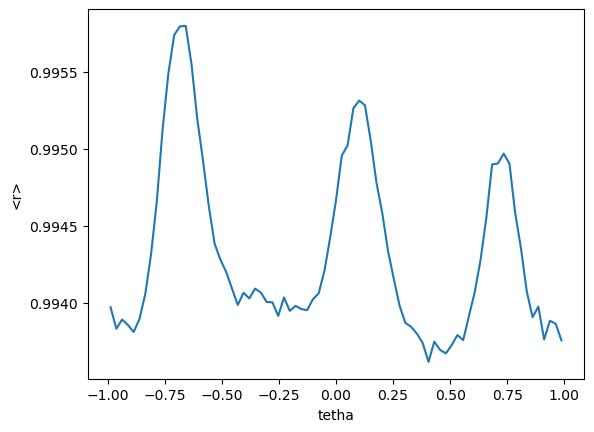

In [107]:
#intergrate over tetha

rho_avg=[]

layer='l_0'

for tetha in range(len(all_combo_hist_OH_water[0,:] )):
  #rho_distribution.append(np.mean(all_combo_hist_OH_water[:,tetha]))
  if np.sum(all_combo_hist_OH_water[tetha]) <= 10000:
    rho_avg.append(0)
  else:
    rho_avg.append(np.average(rho_bins_centers, weights=all_combo_hist_OH_water[tetha] ))
    


plt.plot(theta_bins_centers, rho_avg)
plt.xlabel('tetha')
plt.ylabel('<r>')



save_path="/data/home/salvatorer26/Desktop/group_meeting/bond_theta_2d"
#plt.savefig(f"{save_path}/rho_avg_0", bbox_inches="tight", facecolor="white", transparent=True, dpi=300)

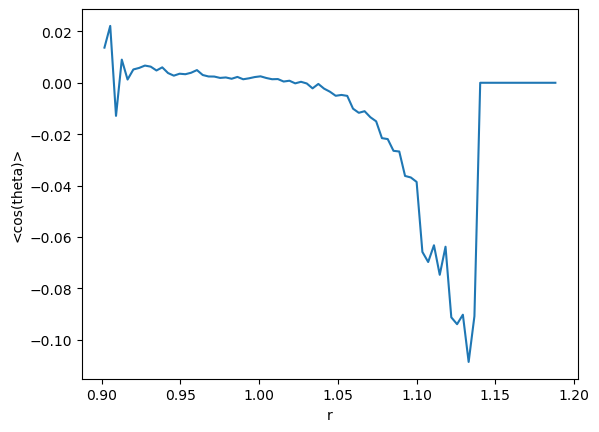

In [108]:

#intergrate over theta

theta_avg=[]


for r in range(len(all_combo_hist_OH_water[0]   )):
  #rho_distribution.append(np.mean(all_combo_hist_OH_water[:,r]))
  if np.sum(all_combo_hist_OH_water[:,r]) <= 1000:
    theta_avg.append(0)
  else:
    theta_avg.append(np.average(theta_bins_centers, weights=all_combo_hist_OH_water[:,r] ))
    


plt.plot(rho_bins_centers, theta_avg)
plt.xlabel('r')
plt.ylabel('<cos(theta)>')



save_path="/data/home/salvatorer26/Desktop/group_meeting/bond_theta_2d"
#plt.savefig(f"{save_path}/avg_0", bbox_inches="tight", facecolor="white", transparent=True, dpi=300)